# Fig4复现
建一个复现文件夹
New-Item -ItemType Directory -Force F:\paper_reproduction
进入
Set-Location F:\paper_reproduction
下载仓库git clone https://github.com/yhr91/GEARS_misc.git


In [ ]:
import sys
import torch

print("Python路径：", sys.executable)
print("PyTorch版本：", torch.__version__)
print("CUDA可用：", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU：", torch.cuda.get_device_name(0))

In [ ]:
from pathlib import Path
import sys

PROJECT_ROOT = Path("F:/paper_reproduction")
REPO_ROOT = PROJECT_ROOT / "GEARS_misc"
DATA_ROOT = PROJECT_ROOT / "data"
NORMAN_PATH = DATA_ROOT / "norman_umi_go"
GENE_PATH = DATA_ROOT / "essential_all_data_pert_genes.pkl"
MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "checkpoint_extracted"
    / "model_ckpt"
)

# 让 Python 能找到仓库中的 gears 文件夹
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

print("代码仓库：", REPO_ROOT)
print("Norman数据：", NORMAN_PATH)
print("辅助基因文件：", GENE_PATH)
print("预训练模型：", MODEL_PATH)

In [ ]:
required_files = {
    "表达数据": NORMAN_PATH / "perturb_processed.h5ad",
    "预处理图": NORMAN_PATH / "data_pyg" / "cell_graphs.pkl",
    "Gene2GO": DATA_ROOT / "gene2go_all.pkl",
    "扰动基因列表": GENE_PATH,
    "模型配置": MODEL_PATH / "config.pkl",
    "模型权重": MODEL_PATH / "model.pt",
}

for name, path in required_files.items():
    status = "存在" if path.exists() else "缺失"
    print(f"{name}：{status}")
    print(f"  {path}")

In [4]:
from gears import PertData, GEARS

print("正在初始化 PertData……")

pert_data = PertData(
    data_path=DATA_ROOT.as_posix(),
    gene_path=GENE_PATH.as_posix()
)

print("正在加载 Norman 数据和预处理图……")

pert_data.load(
    data_path=NORMAN_PATH.as_posix()
)

print("数据加载完成")
print("表达矩阵形状：", pert_data.adata.shape)
print("扰动条件数量：", pert_data.adata.obs["condition"].nunique())
print("扰动图节点数量：", len(pert_data.pert_names))

Done!


数据加载完成
表达矩阵形状： (89357, 5054)
扰动条件数量： 277
扰动图节点数量： 9853


## 2. 准备数据划分和数据加载器

论文 Figure 4 使用 `no_test` 划分。该划分没有独立测试集，而是将已有扰动条件分为训练集和验证集

In [5]:
pert_data.prepare_split(
    split="no_test",
    seed=1
)

print("数据划分包含：", pert_data.set2conditions.keys())

for split_name, conditions in pert_data.set2conditions.items():
    print(f"{split_name}：{len(conditions)} 个扰动条件")

Local copy of split is detected. Loading...
Done!


数据划分包含： dict_keys(['train', 'val'])
train：265 个扰动条件
val：12 个扰动条件


In [6]:
pert_data.get_dataloader(
    batch_size=32,
    test_batch_size=128
)

print("数据加载器：", pert_data.dataloader.keys())
print("训练批次数量：", len(pert_data.dataloader["train_loader"]))
print("验证批次数量：", len(pert_data.dataloader["val_loader"]))

Creating dataloaders....
Done!


数据加载器： dict_keys(['train_loader', 'val_loader'])
训练批次数量： 2698
验证批次数量： 94


## 3. 加载作者训练好的 GEARS 模型

`config.pkl` 保存模型结构以及训练时构建的基因图，`model.pt` 保存训练后得到的参数。

In [7]:
import pickle

config_path = MODEL_PATH / "config.pkl"

with open(config_path, "rb") as file:
    saved_config = pickle.load(file)

print("模型配置包含的字段：")

for key, value in saved_config.items():
    if key in {"G_go", "G_go_weight", "G_coexpress", "G_coexpress_weight"}:
        try:
            print(f"{key}：张量形状 {tuple(value.shape)}")
        except Exception:
            print(f"{key}：{type(value)}")
    else:
        print(f"{key}：{value}")

模型配置包含的字段：
hidden_size：64
num_go_gnn_layers：1
num_gene_gnn_layers：1
decoder_hidden_size：16
num_similar_genes_go_graph：20
num_similar_genes_co_express_graph：20
coexpress_threshold：0.4
uncertainty：False
uncertainty_reg：1
direction_lambda：0.1
G_go：张量形状 (2, 202314)
G_go_weight：张量形状 (202314,)
G_coexpress：张量形状 (2, 7242)
G_coexpress_weight：张量形状 (7242,)
device：cuda:6
num_genes：5054
num_perts：9853
no_perturb：False
cell_fitness_pred：False


In [8]:
device = "cuda:0" if torch.cuda.is_available() else "cpu"
print("模型运行设备：", device)

gears_model = GEARS(
    pert_data=pert_data,
    device=device,
    weight_bias_track=False,
    proj_name="gears",
    exp_name="gears_misc_umi_no_test"
)

print("正在载入预训练参数……")

gears_model.load_pretrained(
    MODEL_PATH.as_posix()
)

print("预训练模型加载成功")
print("隐藏层维度：", gears_model.config["hidden_size"])
print(
    "模型参数所在设备：",
    next(gears_model.best_model.parameters()).device
)

模型运行设备： cuda:0
正在载入预训练参数……
预训练模型加载成功
隐藏层维度： 64
模型参数所在设备： cuda:0


In [9]:
import gc

gears_model.dataloader = None
pert_data.dataloader = None

if hasattr(pert_data, "dataset_processed"):
    del pert_data.dataset_processed

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("已释放不再需要的训练图数据")

已释放不再需要的训练图数据


In [10]:
test_gene = "FEV"

print(
    f"{test_gene} 是否存在于扰动基因图：",
    test_gene in gears_model.pert_list
)

FEV 是否存在于扰动基因图： True


In [11]:
test_prediction = gears_model.predict([[test_gene]])

predicted_expression = test_prediction[test_gene]

print("预测完成")
print("预测向量形状：", predicted_expression.shape)
print("预测表达值前10项：")
print(predicted_expression[:10])

预测完成
预测向量形状： (5054,)
预测表达值前10项：
[ 3.1028977e-03  3.7882096e-01  7.3778018e-02  5.8419544e-01
  4.0600976e-01 -2.0289035e-34  1.0753786e-01  5.6536222e-01
  5.3714573e-01  9.1363880e-04]


## 4. 生成全部扰动组合的预测表达谱

首先从 Norman 数据中找出做过单基因扰动的基因，然后生成这些基因之间所有不重复的两两组合。

如果共有 \(n\) 个基因，需要预测的双基因组合数为：

\[
\binom{n}{2}=\frac{n(n-1)}{2}
\]

In [12]:
from itertools import combinations

observed_conditions = (
    pert_data.adata.obs["condition"]
    .astype(str)
    .unique()
    .tolist()
)

# 找出形如 ctrl+GENE 或 GENE+ctrl 的单基因扰动
observed_single_genes = sorted({
    gene
    for condition in observed_conditions
    if "ctrl" in condition.split("+")
    for gene in condition.split("+")
    if gene != "ctrl"
})

# 只保留存在于GEARS扰动图中的基因
predictable_genes = [
    gene
    for gene in observed_single_genes
    if gene in gears_model.pert_list
]

excluded_genes = sorted(
    set(observed_single_genes) - set(predictable_genes)
)

# 生成无重复组合，例如只保留A+B，不再另外保留B+A
pair_tasks = [
    list(pair)
    for pair in combinations(predictable_genes, 2)
]

single_tasks = [[gene] for gene in predictable_genes]
all_tasks = single_tasks + pair_tasks

print("实验中单基因扰动涉及的基因数：", len(observed_single_genes))
print("GEARS可以预测的基因数：", len(predictable_genes))
print("被GO图排除的基因：", excluded_genes)
print("单基因预测数量：", len(single_tasks))
print("双基因组合数量：", len(pair_tasks))
print("预测任务总数：", len(all_tasks))

实验中单基因扰动涉及的基因数： 102
GEARS可以预测的基因数： 102
被GO图排除的基因： []
单基因预测数量： 102
双基因组合数量： 5151
预测任务总数： 5253


In [13]:
n = len(predictable_genes)
expected_pairs = n * (n - 1) // 2

print("根据公式计算的组合数：", expected_pairs)
print("程序实际生成的组合数：", len(pair_tasks))

assert expected_pairs == len(pair_tasks)

根据公式计算的组合数： 5151
程序实际生成的组合数： 5151


In [14]:
import os
import numpy as np

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "figure4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTION_PATH = (
    OUTPUT_DIR
    / "gears_misc_umi_no_test_all_preds.npy"
)

print("预测结果将保存至：")
print(PREDICTION_PATH)

预测结果将保存至：
F:\paper_reproduction\outputs\figure4\gears_misc_umi_no_test_all_preds.npy


In [15]:
def save_predictions_safely(predictions, output_path):
    """
    先写入临时文件，写完后再替换正式文件。
    避免保存过程中断导致正式文件损坏。
    """
    temporary_path = output_path.with_name(
        output_path.stem + "_temporary.npy"
    )

    np.save(
        temporary_path,
        predictions,
        allow_pickle=True
    )

    os.replace(temporary_path, output_path)

In [16]:
if PREDICTION_PATH.exists():
    saved_predictions = np.load(
        PREDICTION_PATH,
        allow_pickle=True
    ).item()

    gears_model.saved_pred.update(saved_predictions)

    print(
        "发现已有断点，已经载入",
        len(saved_predictions),
        "个预测结果"
    )
else:
    print("未发现已有断点，将从当前进度开始")

未发现已有断点，将从当前进度开始


In [17]:
import time

def task_key(task):
    return "_".join(task)

benchmark_tasks = [
    task
    for task in all_tasks
    if task_key(task) not in gears_model.saved_pred
][:10]

print("本次测试任务数：", len(benchmark_tasks))
print("测试任务：", benchmark_tasks)

if benchmark_tasks:
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    gears_model.predict(benchmark_tasks)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    print(f"10个任务耗时：{elapsed:.1f} 秒")
    print(f"平均每个任务：{elapsed / len(benchmark_tasks):.2f} 秒")
else:
    print("这些任务已经预测过，无需再次测试")

本次测试任务数： 10
测试任务： [['AHR'], ['ARID1A'], ['ARRDC3'], ['ATL1'], ['BAK1'], ['BCL2L11'], ['BCORL1'], ['BPGM'], ['C19orf26'], ['C3orf72']]
10个任务耗时：1.2 秒
平均每个任务：0.12 秒


In [18]:
save_predictions_safely(
    gears_model.saved_pred,
    PREDICTION_PATH
)

print("当前已保存预测数：", len(gears_model.saved_pred))

当前已保存预测数： 11


In [19]:
remaining_tasks = [
    task
    for task in all_tasks
    if task_key(task) not in gears_model.saved_pred
]

if benchmark_tasks:
    seconds_per_task = elapsed / len(benchmark_tasks)
    estimated_hours = (
        len(remaining_tasks) * seconds_per_task / 3600
    )

    print("剩余任务数：", len(remaining_tasks))
    print(f"粗略预计还需：{estimated_hours:.2f} 小时")

剩余任务数： 5242
粗略预计还需：0.18 小时


In [20]:
from tqdm.auto import tqdm

pending_tasks = [
    task
    for task in all_tasks
    if task_key(task) not in gears_model.saved_pred
]

# 每次交给模型20个任务
prediction_batch_size = 20

# 每完成约100个任务保存一次
save_every = 100
completed_since_save = 0

print("等待预测的任务数：", len(pending_tasks))

progress = tqdm(
    total=len(pending_tasks),
    desc="预测扰动组合",
    unit="个"
)

try:
    for start in range(
        0,
        len(pending_tasks),
        prediction_batch_size
    ):
        batch = pending_tasks[
            start:start + prediction_batch_size
        ]

        gears_model.predict(batch)

        progress.update(len(batch))
        completed_since_save += len(batch)

        if completed_since_save >= save_every:
            save_predictions_safely(
                gears_model.saved_pred,
                PREDICTION_PATH
            )

            completed_since_save = 0

    # 全部完成后再保存一次
    save_predictions_safely(
        gears_model.saved_pred,
        PREDICTION_PATH
    )

finally:
    progress.close()

print("全部预测完成")
print("已保存预测数量：", len(gears_model.saved_pred))

等待预测的任务数： 5242


预测扰动组合:   0%|          | 0/5242 [00:00<?, ?个/s]

全部预测完成
已保存预测数量： 5253


In [21]:
saved_predictions = np.load(
    PREDICTION_PATH,
    allow_pickle=True
).item()

expected_keys = {
    task_key(task)
    for task in all_tasks
}

missing_keys = expected_keys - set(saved_predictions)

print("文件中预测数量：", len(saved_predictions))
print("本次任务应有数量：", len(expected_keys))
print("缺失数量：", len(missing_keys))

assert len(missing_keys) == 0

print("所有预测均已完成并正确保存")

文件中预测数量： 5253
本次任务应有数量： 5253
缺失数量： 0
所有预测均已完成并正确保存


## 5. 构建用于 UMAP 的预测表达矩阵

每一行代表一种扰动条件，每一列代表一个基因。矩阵共有 5253 行和 5054 列。

In [22]:
import pandas as pd
import scanpy as sc

# 按固定顺序排列，保证下次重新运行时结果顺序一致
ordered_tasks = single_tasks + pair_tasks
ordered_keys = [task_key(task) for task in ordered_tasks]

prediction_matrix = np.vstack([
    saved_predictions[key]
    for key in ordered_keys
]).astype(np.float32)

print("预测表达矩阵形状：", prediction_matrix.shape)

assert prediction_matrix.shape[0] == 5253
assert prediction_matrix.shape[1] == pert_data.adata.shape[1]

预测表达矩阵形状： (5253, 5054)


In [23]:
# 实验中真正测量过的双基因组合
observed_pair_sets = {
    frozenset(
        gene
        for gene in condition.split("+")
        if gene != "ctrl"
    )
    for condition in observed_conditions
    if "ctrl" not in condition.split("+")
    and len(condition.split("+")) == 2
}

metadata = []

for task, key in zip(ordered_tasks, ordered_keys):
    if len(task) == 1:
        perturbation_type = "single"
        seen = True
    else:
        perturbation_type = "pair"
        seen = frozenset(task) in observed_pair_sets

    metadata.append({
        "prediction_key": key,
        "perturbation": "+".join(task),
        "perturbation_type": perturbation_type,
        "seen": seen
    })

prediction_metadata = pd.DataFrame(metadata)
prediction_metadata.index = ordered_keys

display(
    pd.crosstab(
        prediction_metadata["perturbation_type"],
        prediction_metadata["seen"],
        margins=True
    )
)

seen,False,True,All
perturbation_type,,,
pair,5023,128,5151
single,0,102,102
All,5023,230,5253


In [24]:
pred_adata = sc.AnnData(
    X=prediction_matrix,
    obs=prediction_metadata.copy()
)

pred_adata.var_names = (
    pert_data.adata.var["gene_name"]
    .astype(str)
    .values
)

pred_adata.var_names_make_unique()

pred_adata.obs["seen"] = (
    pred_adata.obs["seen"]
    .astype(bool)
)

pred_adata.obs["seen_label"] = pd.Categorical(
    np.where(
        pred_adata.obs["seen"],
        "Seen perturbation",
        "Unseen prediction"
    )
)

print(pred_adata)
print("已观察扰动：", pred_adata.obs["seen"].sum())
print("未观察预测：", (~pred_adata.obs["seen"]).sum())

AnnData object with n_obs × n_vars = 5253 × 5054
    obs: 'prediction_key', 'perturbation', 'perturbation_type', 'seen', 'seen_label'
已观察扰动： 230
未观察预测： 5023


In [25]:
import umap
import time

print("开始计算全部5253种扰动的UMAP……")

start_time = time.perf_counter()

full_umap_model = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="euclidean",
    random_state=1,
    low_memory=True,
    verbose=True
)

pred_adata.obsm["X_umap"] = (
    full_umap_model.fit_transform(pred_adata.X)
)

elapsed = time.perf_counter() - start_time

print(f"完整UMAP计算完成，用时：{elapsed / 60:.2f} 分钟")
print("UMAP坐标形状：", pred_adata.obsm["X_umap"].shape)

开始计算全部5253种扰动的UMAP……
UMAP(n_jobs=1, random_state=1, verbose=True)
Sat Oct 10 09:38:10 2026 Construct fuzzy simplicial set
Sat Oct 10 09:38:10 2026 Finding Nearest Neighbors
Sat Oct 10 09:38:10 2026 Building RP forest with 9 trees
Sat Oct 10 09:38:13 2026 NN descent for 12 iterations
	 1  /  12
	 2  /  12
	Stopping threshold met -- exiting after 2 iterations
Sat Oct 10 09:38:26 2026 Finished Nearest Neighbor Search
Sat Oct 10 09:38:29 2026 Construct embedding


Epochs completed:   0%|            0/500 [00:00]

	completed  0  /  500 epochs
	completed  50  /  500 epochs
	completed  100  /  500 epochs
	completed  150  /  500 epochs
	completed  200  /  500 epochs
	completed  250  /  500 epochs
	completed  300  /  500 epochs
	completed  350  /  500 epochs
	completed  400  /  500 epochs
	completed  450  /  500 epochs
Sat Oct 10 09:38:34 2026 Finished embedding
完整UMAP计算完成，用时：0.40 分钟
UMAP坐标形状： (5253, 2)


In [26]:
print("正在构建全部预测的邻居图……")

sc.pp.neighbors(
    pred_adata,
    n_neighbors=15,
    use_rep="X",
    random_state=1
)

print("正在进行Leiden聚类……")

sc.tl.leiden(
    pred_adata,
    resolution=1.0,
    random_state=1,
    key_added="leiden_full",
    flavor="leidenalg"
)

print("Leiden聚类数量：", pred_adata.obs["leiden_full"].nunique())

cluster_summary = (
    pred_adata.obs
    .groupby("leiden_full", observed=True)
    .agg(
        点数=("prediction_key", "size"),
        已观察数量=("seen", "sum")
    )
)

cluster_summary["未观察数量"] = (
    cluster_summary["点数"]
    - cluster_summary["已观察数量"]
)

display(cluster_summary)

正在构建全部预测的邻居图……
正在进行Leiden聚类……
Leiden聚类数量： 22


,点数,已观察数量,未观察数量
leiden_full,,,
0,427,10,417
1,395,12,383
2,369,11,358
3,365,43,322
4,331,23,308
5,303,20,283
6,270,4,266
7,256,6,250
8,254,6,248


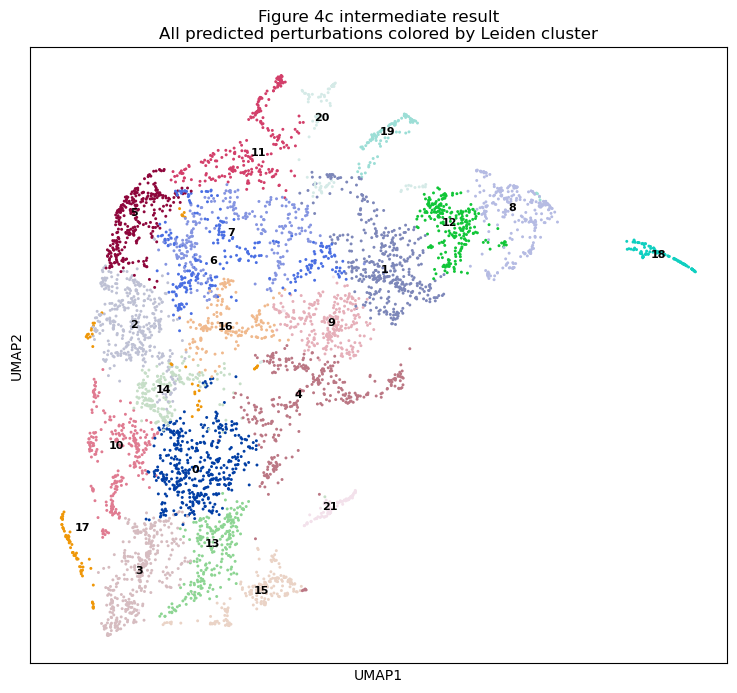

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 8))

sc.pl.umap(
    pred_adata,
    color="leiden_full",
    legend_loc="on data",
    legend_fontsize=8,
    size=18,
    frameon=True,
    ax=ax,
    show=False
)

ax.set_title(
    "Figure 4c intermediate result\n"
    "All predicted perturbations colored by Leiden cluster"
)

plt.show()

In [28]:
seen_adata = pred_adata[
    pred_adata.obs["seen"]
].copy()

print("Figure 4b包含的扰动数量：", seen_adata.n_obs)

sc.pp.neighbors(
    seen_adata,
    n_neighbors=15,
    use_rep="X",
    random_state=1
)

sc.tl.umap(
    seen_adata,
    random_state=1
)

sc.tl.leiden(
    seen_adata,
    resolution=1.0,
    random_state=1,
    key_added="leiden_seen",
    flavor="leidenalg"
)

print(
    "Figure 4b的Leiden聚类数量：",
    seen_adata.obs["leiden_seen"].nunique()
)

Figure 4b包含的扰动数量： 230
Figure 4b的Leiden聚类数量： 8


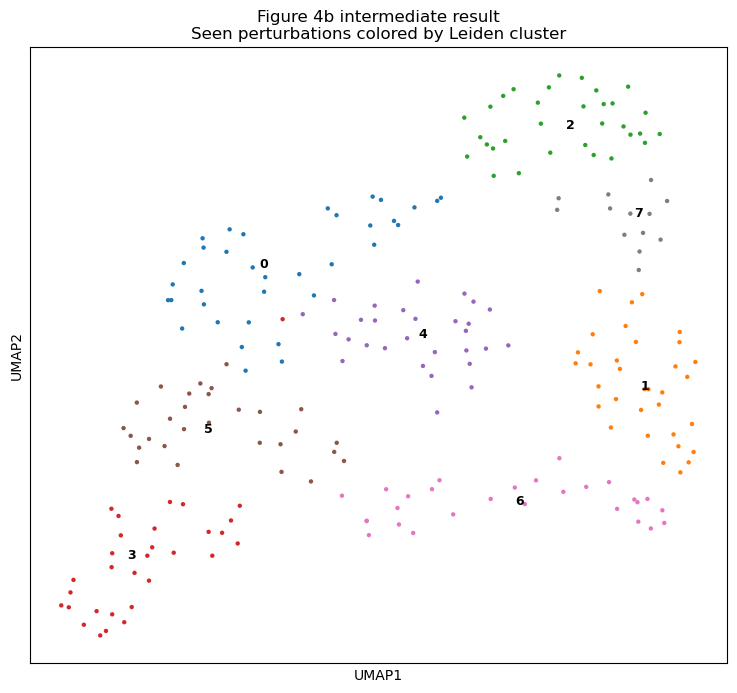

In [29]:
fig, ax = plt.subplots(figsize=(9, 8))

sc.pl.umap(
    seen_adata,
    color="leiden_seen",
    legend_loc="on data",
    legend_fontsize=9,
    size=40,
    frameon=True,
    ax=ax,
    show=False
)

ax.set_title(
    "Figure 4b intermediate result\n"
    "Seen perturbations colored by Leiden cluster"
)

plt.show()

In [30]:
FULL_ADATA_PATH = (
    OUTPUT_DIR
    / "figure4_all_predictions_clustered.h5ad"
)

SEEN_ADATA_PATH = (
    OUTPUT_DIR
    / "figure4_seen_predictions_clustered.h5ad"
)

pred_adata.write_h5ad(
    FULL_ADATA_PATH,
    compression="gzip"
)

seen_adata.write_h5ad(
    SEEN_ADATA_PATH,
    compression="gzip"
)

print("完整预测数据已保存至：", FULL_ADATA_PATH)
print("Seen扰动数据已保存至：", SEEN_ADATA_PATH)

完整预测数据已保存至： F:\paper_reproduction\outputs\figure4\figure4_all_predictions_clustered.h5ad
Seen扰动数据已保存至： F:\paper_reproduction\outputs\figure4\figure4_seen_predictions_clustered.h5ad


## 6. 根据标志基因解释 Leiden 聚类

Leiden 只负责把相似的预测表达谱分组，并不知道每个群的生物学含义。下面根据红系、巨核细胞、粒细胞及细胞增殖相关标志基因，为各群计算表达得分。

In [31]:
marker_panels = {
    "Erythroid": [
        "HBA1", "HBA2", "HBB", "HBG1", "HBG2",
        "HBZ", "GYPA", "KLF1", "ALAS2", "SLC4A1"
    ],
    "Megakaryocyte": [
        "PF4", "PPBP", "ITGA2B", "GP1BA",
        "GP9", "NFE2", "FLI1"
    ],
    "Granulocyte": [
        "MPO", "ELANE", "CSF3R", "CEBPE",
        "CEBPA", "SPI1", "FCGR3B"
    ],
    "Pro_growth": [
        "MKI67", "PCNA", "TYMS", "MCM2",
        "MCM5", "TOP2A", "CDK1"
    ]
}

for panel_name, genes in marker_panels.items():
    available = [gene for gene in genes if gene in pred_adata.var_names]
    missing = [gene for gene in genes if gene not in pred_adata.var_names]

    print(f"\n{panel_name}")
    print("数据中存在：", available)
    print("数据中缺失：", missing)


Erythroid
数据中存在： ['HBA1', 'HBA2', 'HBB', 'HBG1', 'HBG2', 'HBZ', 'GYPA', 'KLF1', 'ALAS2', 'SLC4A1']
数据中缺失： []

Megakaryocyte
数据中存在： ['NFE2']
数据中缺失： ['PF4', 'PPBP', 'ITGA2B', 'GP1BA', 'GP9', 'FLI1']

Granulocyte
数据中存在： ['ELANE', 'CSF3R', 'CEBPE', 'CEBPA', 'SPI1']
数据中缺失： ['MPO', 'FCGR3B']

Pro_growth
数据中存在： ['MKI67', 'PCNA', 'TYMS', 'MCM5', 'TOP2A', 'CDK1']
数据中缺失： ['MCM2']


In [32]:
def add_marker_scores(adata, panels):
    available_panels = {}

    all_genes = sorted({
        gene
        for genes in panels.values()
        for gene in genes
        if gene in adata.var_names
    })

    marker_expression = pd.DataFrame(
        np.asarray(adata[:, all_genes].X),
        index=adata.obs_names,
        columns=all_genes
    )

    marker_std = marker_expression.std(axis=0)
    marker_std = marker_std.replace(0, np.nan)

    marker_z = (
        marker_expression - marker_expression.mean(axis=0)
    ) / marker_std

    for panel_name, genes in panels.items():
        available = [
            gene for gene in genes
            if gene in marker_z.columns
        ]

        available_panels[panel_name] = available

        if available:
            adata.obs[f"{panel_name}_score"] = (
                marker_z[available].mean(axis=1)
            )
        else:
            adata.obs[f"{panel_name}_score"] = 0.0

    return available_panels

In [33]:
full_available_panels = add_marker_scores(
    pred_adata,
    marker_panels
)

seen_available_panels = add_marker_scores(
    seen_adata,
    marker_panels
)

print("标志基因得分计算完成")

标志基因得分计算完成


In [34]:
score_columns = [
    f"{panel_name}_score"
    for panel_name in marker_panels
]

full_cluster_scores = (
    pred_adata.obs
    .groupby("leiden_full", observed=True)[score_columns]
    .mean()
    .round(2)
)

display(
    full_cluster_scores.style.background_gradient(
        cmap="RdBu_r",
        axis=0
    )
)

,Erythroid_score,Megakaryocyte_score,Granulocyte_score,Pro_growth_score
leiden_full,,,,
0,-0.440000,-0.690000,-0.330000,0.450000
1,-0.130000,0.150000,0.330000,-0.430000
2,0.490000,0.180000,-0.410000,0.240000
3,-0.750000,-1.210000,-0.610000,0.730000
4,-0.750000,-0.680000,0.240000,0.140000
5,1.130000,0.870000,-0.460000,0.050000
6,0.450000,0.510000,-0.090000,-0.250000
7,0.780000,0.660000,-0.230000,0.090000
8,-0.230000,0.480000,1.170000,-1.070000


In [35]:
for score_name in score_columns:
    print(f"\n{score_name}最高的5个群：")

    display(
        full_cluster_scores[score_name]
        .sort_values(ascending=False)
        .head(5)
        .to_frame()
    )


Erythroid_score最高的5个群：


,Erythroid_score
leiden_full,
11,1.92
19,1.38
5,1.13
20,0.81
7,0.78



Megakaryocyte_score最高的5个群：


,Megakaryocyte_score
leiden_full,
19,2.24
11,1.78
18,1.00
20,0.98
5,0.87



Granulocyte_score最高的5个群：


,Granulocyte_score
leiden_full,
18,4.09
8,1.17
12,0.66
19,0.33
1,0.33



Pro_growth_score最高的5个群：


,Pro_growth_score
leiden_full,
3,0.73
15,0.67
17,0.66
13,0.56
10,0.50


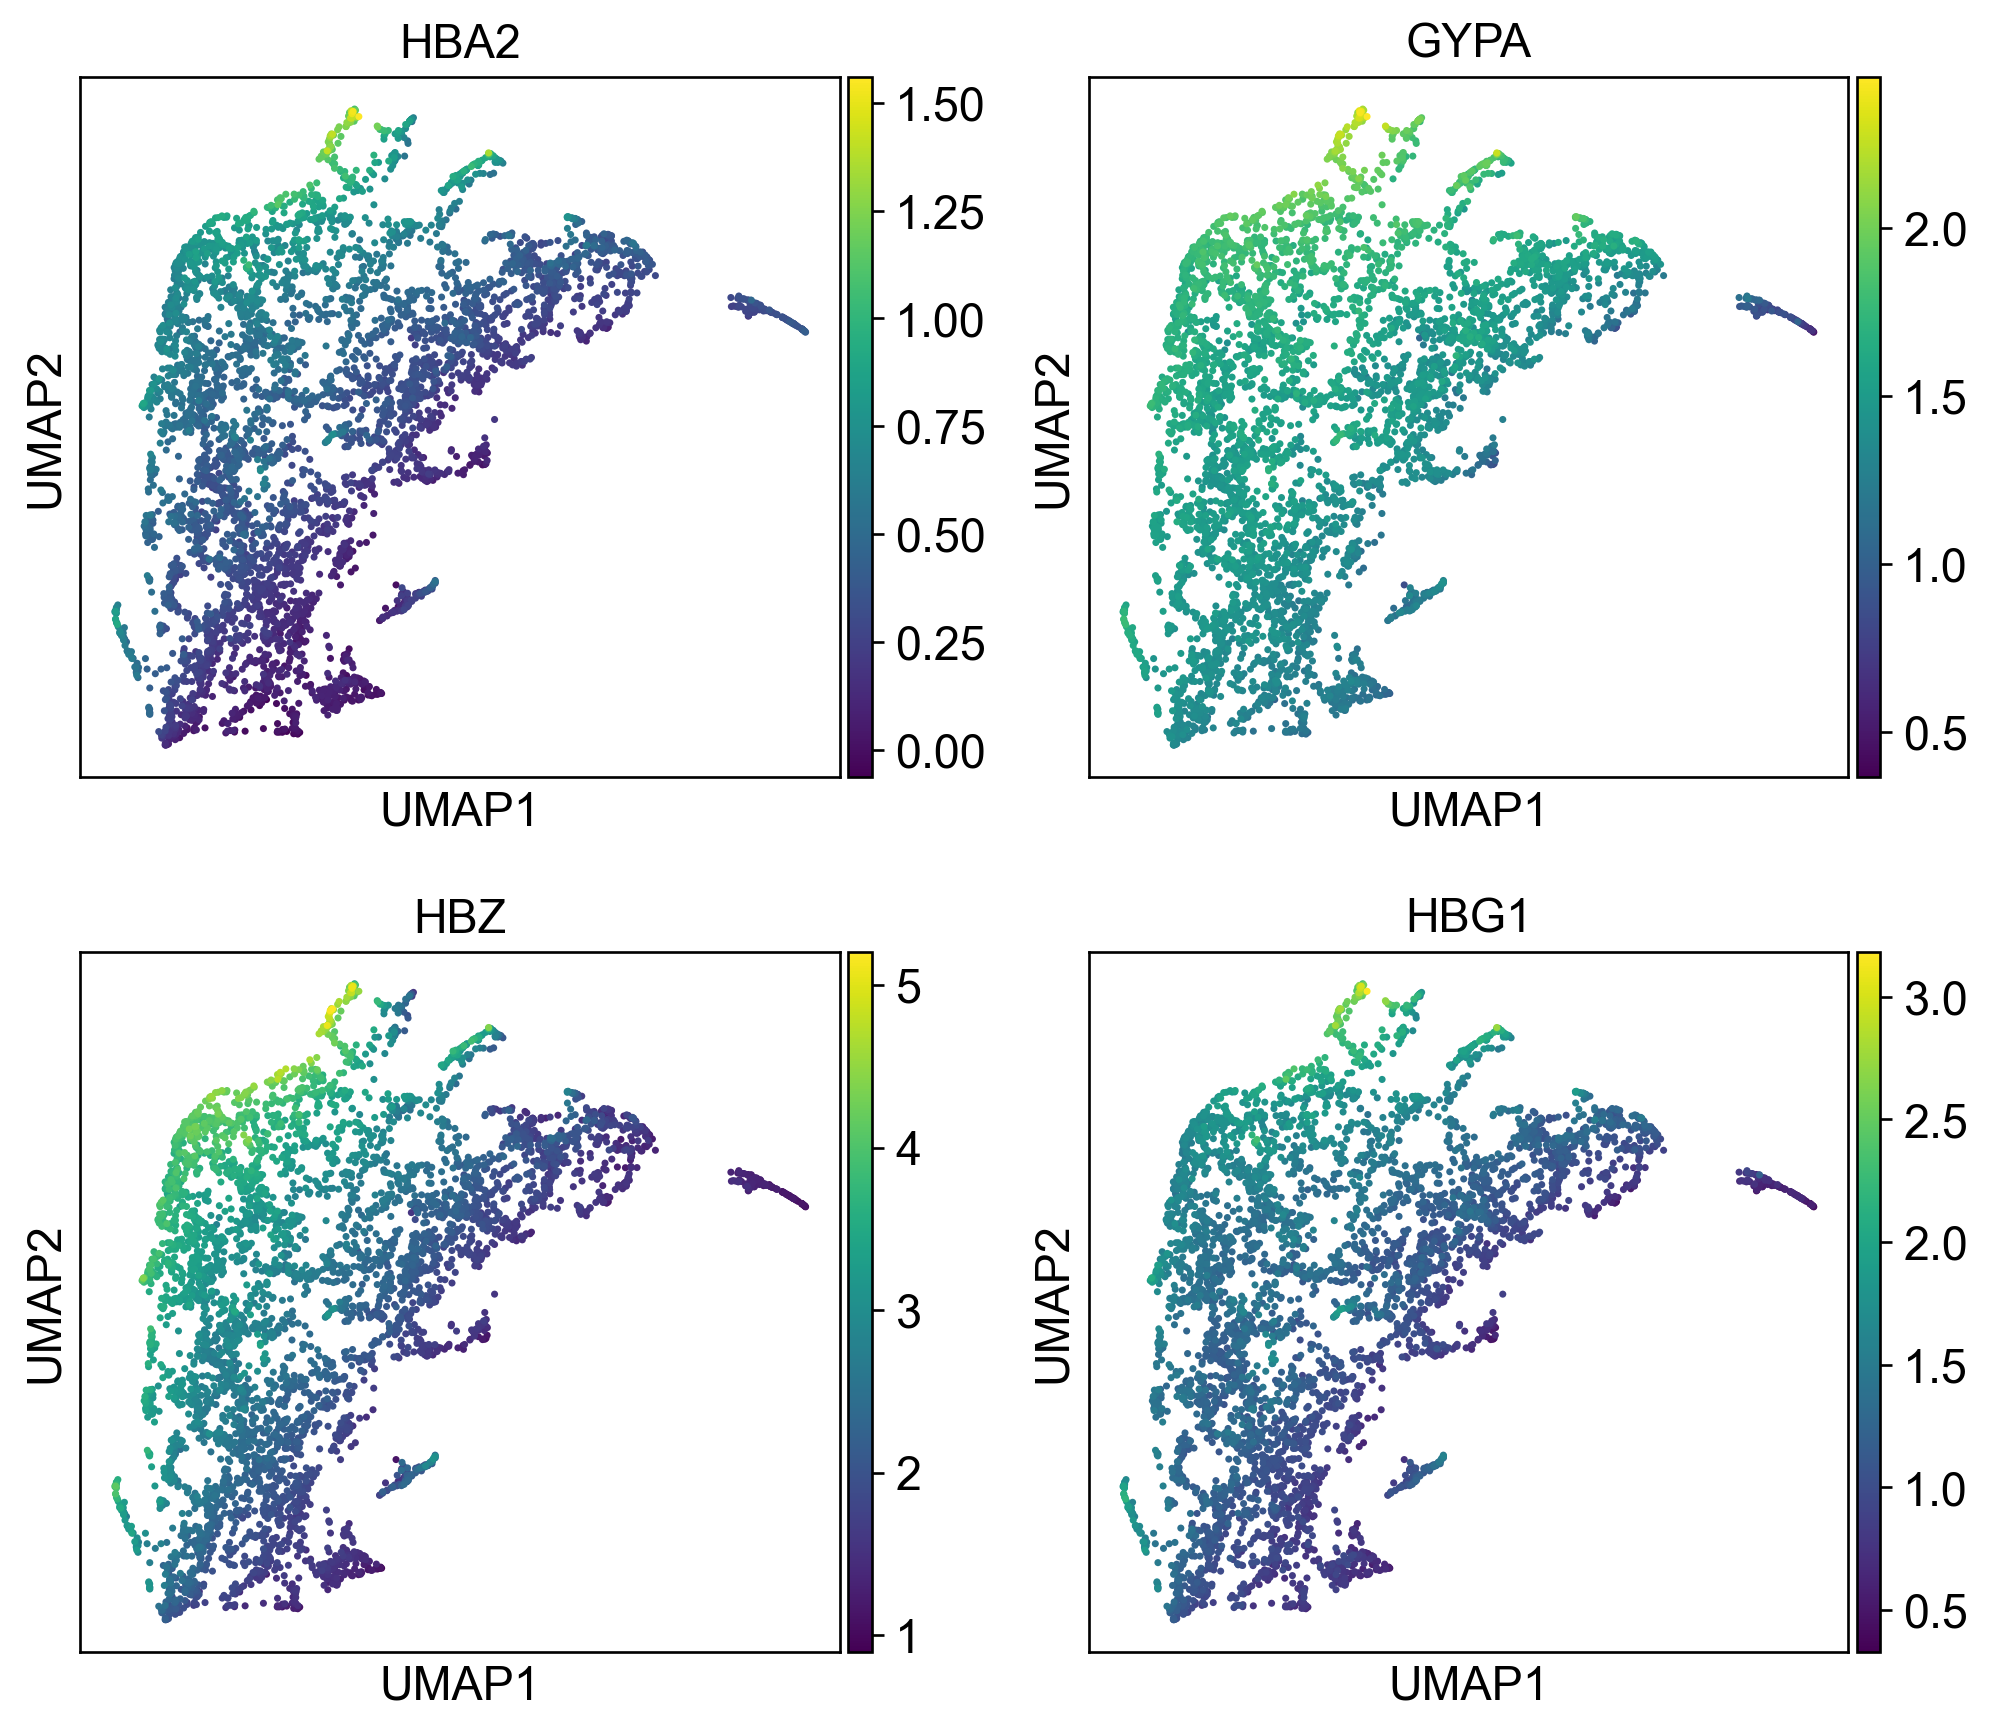

In [36]:
erythroid_markers = [
    gene
    for gene in ["HBA2", "GYPA", "HBZ", "HBG1"]
    if gene in pred_adata.var_names
]

sc.set_figure_params(
    figsize=(4, 4),
    dpi=120
)

sc.pl.umap(
    pred_adata,
    color=erythroid_markers,
    cmap="viridis",
    size=18,
    ncols=2,
    frameon=True
)

In [37]:
from collections import Counter

def show_cluster_representatives(
    adata,
    cluster_key,
    clusters=None,
    n_representatives=8
):
    labels = adata.obs[cluster_key].astype(str).values
    coordinates = adata.obsm["X_umap"]

    if clusters is None:
        clusters = sorted(
            np.unique(labels),
            key=lambda x: int(x)
        )

    for cluster in clusters:
        positions = np.flatnonzero(labels == str(cluster))
        cluster_coordinates = coordinates[positions]

        centroid = cluster_coordinates.mean(axis=0)

        distances = np.sum(
            (cluster_coordinates - centroid) ** 2,
            axis=1
        )

        representative_positions = positions[
            np.argsort(distances)[:n_representatives]
        ]

        representative_perts = (
            adata.obs.iloc[representative_positions]
            ["perturbation"]
            .tolist()
        )

        all_target_genes = [
            gene
            for perturbation in adata.obs.iloc[positions]["perturbation"]
            for gene in perturbation.split("+")
        ]

        frequent_targets = Counter(
            all_target_genes
        ).most_common(6)

        seen_count = int(
            adata.obs.iloc[positions]["seen"].sum()
        )

        print(f"\nCluster {cluster}")
        print(
            f"点数：{len(positions)}；"
            f"seen数量：{seen_count}"
        )
        print("中心附近扰动：", representative_perts)
        print("常见被扰动基因：", frequent_targets)

In [38]:
show_cluster_representatives(
    seen_adata,
    cluster_key="leiden_seen",
    n_representatives=10
)


Cluster 0
点数：35；seen数量：35
中心附近扰动： ['RREB1', 'C19orf26+TGFBR2', 'ZBTB1', 'S1PR2', 'FOSB+PTPN12', 'DUSP9+ETS2', 'IGDCC3', 'KLF1+SET', 'CBL', 'ETS2+IGDCC3']
常见被扰动基因： [('ETS2', 4), ('PTPN12', 3), ('SET', 3), ('SGK1', 3), ('TBX2', 3), ('TBX3', 3)]

Cluster 1
点数：33；seen数量：33
中心附近扰动： ['FOXA1+HOXB9', 'FOXF1+HOXB9', 'HOXA13', 'FOXA1+FOXA3', 'FOXL2+POU3F2', 'FOXA1+FOXL2', 'ZBTB10', 'ELMSAN1+ZBTB10', 'FOXA3+FOXF1', 'FOXF1+FOXL2']
常见被扰动基因： [('FOXL2', 7), ('ZBTB10', 5), ('FEV', 4), ('FOXA3', 4), ('HOXB9', 4), ('CBFA2T3', 3)]

Cluster 2
点数：32；seen数量：32
中心附近扰动： ['PTPN1', 'CBL+UBASH3A', 'CDKN1A+CDKN1C', 'PTPN12+UBASH3A', 'CDKN1B+CDKN1C', 'SAMD1+UBASH3B', 'IGDCC3+ZBTB25', 'PTPN12+UBASH3B', 'CDKN1A+CDKN1B', 'CBL+PTPN9']
常见被扰动基因： [('UBASH3B', 7), ('CBL', 6), ('PTPN12', 6), ('SAMD1', 4), ('TGFBR2', 4), ('UBASH3A', 4)]

Cluster 3
点数：31；seen数量：31
中心附近扰动： ['BAK1', 'CSRNP1', 'MAML2', 'RUNX1T1', 'MAP7D1', 'BCL2L11', 'ELMSAN1', 'BAK1+BCL2L11', 'BCORL1', 'ZNF318']
常见被扰动基因： [('KLF1', 5), ('BAK1', 4), ('MAP2K3', 

In [39]:
show_cluster_representatives(
    pred_adata,
    cluster_key="leiden_full",
    n_representatives=6
)


Cluster 0
点数：427；seen数量：10
中心附近扰动： ['MEIS1+TSC22D1', 'KIF18B+KIF2C', 'C19orf26+SLC4A1', 'FOXA3+MAML2', 'CSRNP1+FOXA1', 'IRF1+KIF2C']
常见被扰动基因： [('ELMSAN1', 28), ('KMT2A', 25), ('TMSB4X', 24), ('MAP4K3', 24), ('CSRNP1', 23), ('BCORL1', 22)]

Cluster 1
点数：395；seen数量：12
中心附近扰动： ['FOXA3+POU3F2', 'NIT1+PTPN13', 'HOXB9+RREB1', 'HOXC13+NCL', 'CITED1+MEIS1', 'ARID1A+CELF2']
常见被扰动基因： [('MIDN', 30), ('C3orf72', 29), ('HOXC13', 28), ('CITED1', 23), ('ARID1A', 22), ('HOXB9', 22)]

Cluster 2
点数：369；seen数量：11
中心附近扰动： ['IGDCC3+KIF2C', 'CDKN1A+CSRNP1', 'UBASH3A+ZBTB25', 'HK2+UBASH3B', 'PTPN9+SLC6A9', 'ARRDC3+UBASH3B']
常见被扰动基因： [('BPGM', 28), ('CNNM4', 25), ('UBASH3B', 24), ('ZBTB25', 24), ('PTPN12', 23), ('IGDCC3', 22)]

Cluster 3
点数：365；seen数量：43
中心附近扰动： ['MAP4K3+SLC38A2', 'IRF1+MAP2K6', 'MAP4K3+ZC3HAV1', 'KIF18B+SLC38A2', 'MAP2K6+PTPN13', 'BCL2L11+TSC22D1']
常见被扰动基因： [('MAP2K3', 54), ('MAP2K6', 53), ('ZC3HAV1', 39), ('SLC38A2', 37), ('BAK1', 35), ('BCL2L11', 29)]

Cluster 4
点数：331；seen数量：23
中心附近扰动： [

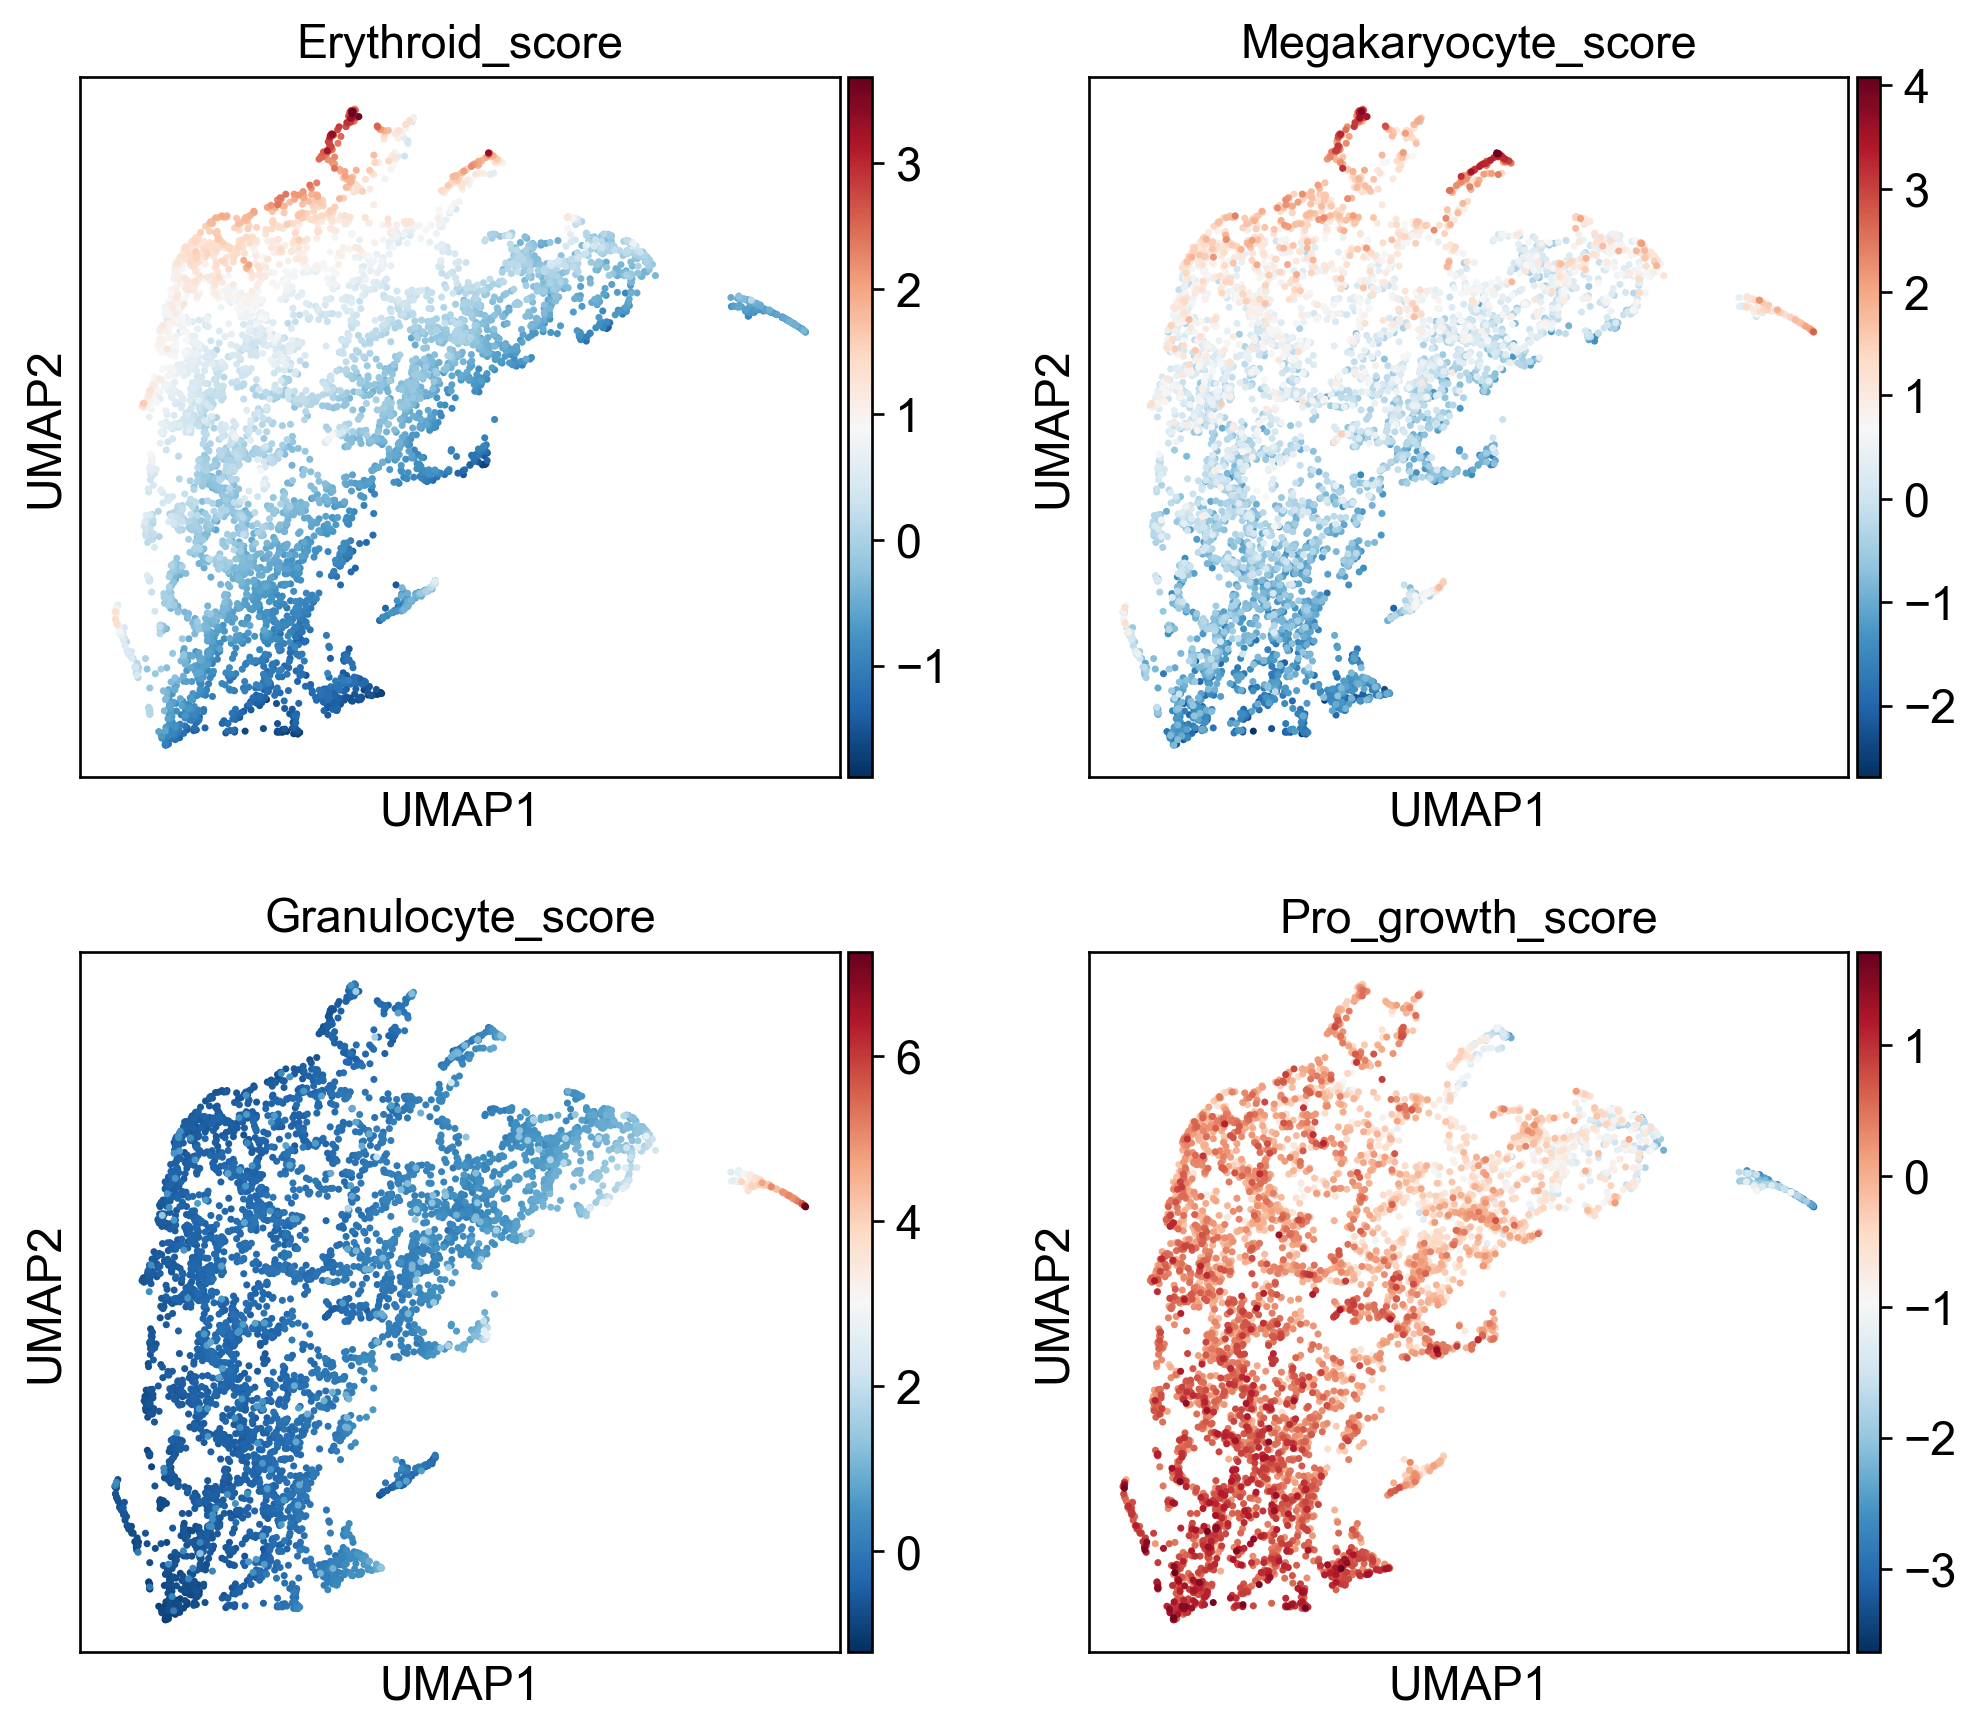

In [40]:
sc.pl.umap(
    pred_adata,
    color=score_columns,
    cmap="RdBu_r",
    size=18,
    ncols=2,
    frameon=True
)

In [41]:
high_erythroid_anchors = [
    "IKZF3+PRDM1",
    "ATL1+FEV",
    "IKZF3+SPI1"
]

for anchor in high_erythroid_anchors:
    anchor_genes = set(anchor.split("+"))

    matched = pred_adata.obs[
        pred_adata.obs["perturbation"].apply(
            lambda value: set(value.split("+")) == anchor_genes
        )
    ]

    print(f"\n{anchor}")
    
    if len(matched) == 0:
        print("没有找到")
    else:
        display(
            matched[
                [
                    "perturbation",
                    "leiden_full",
                    "seen",
                    "Erythroid_score",
                    "Megakaryocyte_score",
                    "Granulocyte_score",
                    "Pro_growth_score"
                ]
            ]
        )


IKZF3+PRDM1


,perturbation,leiden_full,seen,Erythroid_score,Megakaryocyte_score,Granulocyte_score,Pro_growth_score
IKZF3_PRDM1,IKZF3+PRDM1,11,False,3.683711,3.842483,-0.525637,-0.392237



ATL1+FEV


,perturbation,leiden_full,seen,Erythroid_score,Megakaryocyte_score,Granulocyte_score,Pro_growth_score
ATL1_FEV,ATL1+FEV,20,False,2.052756,1.774827,-0.307923,-0.070959



IKZF3+SPI1


,perturbation,leiden_full,seen,Erythroid_score,Megakaryocyte_score,Granulocyte_score,Pro_growth_score
IKZF3_SPI1,IKZF3+SPI1,19,False,1.862798,2.366909,0.113021,-0.735532


In [42]:
candidate_clusters = [
    "1", "3", "4", "5", "8",
    "11", "15", "17", "18", "19", "20"
]

candidate_summary = (
    pred_adata.obs[
        pred_adata.obs["leiden_full"]
        .astype(str)
        .isin(candidate_clusters)
    ]
    .groupby("leiden_full", observed=True)
    .agg(
        点数=("perturbation", "size"),
        seen数量=("seen", "sum"),
        Erythroid_score=("Erythroid_score", "mean"),
        Megakaryocyte_score=("Megakaryocyte_score", "mean"),
        Granulocyte_score=("Granulocyte_score", "mean"),
        Pro_growth_score=("Pro_growth_score", "mean")
    )
    .round(2)
)

display(candidate_summary)

,点数,seen数量,Erythroid_score,Megakaryocyte_score,Granulocyte_score,Pro_growth_score
leiden_full,,,,,,
1,395,12,-0.13,0.15,0.33,-0.43
3,365,43,-0.75,-1.21,-0.61,0.73
4,331,23,-0.75,-0.68,0.24,0.14
5,303,20,1.13,0.87,-0.46,0.05
8,254,6,-0.23,0.48,1.17,-1.07
11,250,8,1.92,1.78,-0.37,-0.06
15,185,10,-1.41,-1.59,0.14,0.67
17,107,9,0.64,0.06,-0.62,0.66
18,106,7,-0.65,1.00,4.09,-2.19


In [43]:
pioneer_factor_genes = {
    "FOXA1", "FOXA3", "FOXF1", "FOXL2",
    "HNF4A", "HOXA13", "HOXB9", "HOXC13",
    "POU3F2", "MEIS1", "LHX1"
}

pred_adata.obs["pioneer_target_count"] = [
    sum(
        gene in pioneer_factor_genes
        for gene in perturbation.split("+")
    )
    for perturbation in pred_adata.obs["perturbation"]
]

pioneer_summary = (
    pred_adata.obs
    .groupby("leiden_full", observed=True)
    .agg(
        点数=("perturbation", "size"),
        先锋因子出现总次数=("pioneer_target_count", "sum"),
        平均每个扰动包含先锋因子数=("pioneer_target_count", "mean")
    )
    .sort_values(
        "平均每个扰动包含先锋因子数",
        ascending=False
    )
)

display(pioneer_summary.head(8))

,点数,先锋因子出现总次数,平均每个扰动包含先锋因子数
leiden_full,,,
8,254,120,0.472441
12,246,113,0.459350
1,395,178,0.450633
9,252,93,0.369048
16,168,58,0.345238
20,100,28,0.280000
4,331,88,0.265861
0,427,111,0.259953


In [44]:
show_cluster_representatives(
    seen_adata,
    cluster_key="leiden_seen",
    clusters=["5", "6"],
    n_representatives=10
)


Cluster 5
点数：29；seen数量：29
中心附近扰动： ['HK2', 'CNN1+MAPK1', 'MAP4K5', 'MEIS1', 'OSR2+PTPN12', 'FOSB+UBASH3B', 'MAPK1+PRTG', 'ARRDC3', 'IRF1', 'UBASH3A']
常见被扰动基因： [('MAPK1', 3), ('ARRDC3', 1), ('C19orf26', 1), ('CBFA2T3', 1), ('DLX2', 1), ('EGR1', 1)]

Cluster 6
点数：28；seen数量：28
中心附近扰动： ['CEBPB+MAPK1', 'CEBPE+ETS2', 'FOSB+OSR2', 'CEBPE', 'CEBPB+OSR2', 'ETS2+MAPK1', 'CEBPB', 'CEBPE+RUNX1T1', 'CEBPE+FOSB', 'CEBPE+ZC3HAV1']
常见被扰动基因： [('CEBPE', 9), ('CEBPA', 6), ('CEBPB', 6), ('ETS2', 4), ('FOSB', 4), ('MAPK1', 4)]


In [45]:
seen_cluster_scores = (
    seen_adata.obs
    .groupby("leiden_seen", observed=True)[score_columns]
    .mean()
    .round(2)
)

display(
    seen_cluster_scores.style.background_gradient(
        cmap="RdBu_r",
        axis=0
    )
)

,Erythroid_score,Megakaryocyte_score,Granulocyte_score,Pro_growth_score
leiden_seen,,,,
0,0.120000,0.030000,-0.310000,0.200000
1,0.080000,0.550000,0.310000,-0.670000
2,1.150000,1.000000,-0.320000,-0.030000
3,-0.560000,-1.130000,-0.570000,0.590000
4,-0.260000,-0.270000,-0.040000,-0.020000
5,-0.510000,-0.700000,-0.310000,0.430000
6,-0.980000,-0.370000,1.480000,-0.440000
7,1.800000,1.750000,-0.260000,-0.160000


In [46]:
figure4c_cluster_map = {
    "1": "Pioneer factors",
    "4": "Pioneer factors",

    "3": "Progrowth",
    "15": "Progrowth",
    "17": "Progrowth",

    "5": "Erythroid marker",

    "8": "Granulocyte marker",
    "18": "Granulocyte marker",

    "19": "Megakaryocyte marker",

    "11": "High erythroid marker expression (new)"
}

pred_adata.obs["phenotype_4c"] = (
    pred_adata.obs["leiden_full"]
    .astype(str)
    .map(figure4c_cluster_map)
    .fillna("Other predicted perturbation")
)

figure4b_cluster_map = {
    "0": "Other seen perturbation",
    "1": "Pioneer factors",
    "2": "Megakaryocyte marker",
    "3": "Progrowth",
    "4": "Pioneer factors",
    "5": "Progrowth",
    "6": "Granulocyte marker",
    "7": "Erythroid marker"
}

seen_adata.obs["phenotype_4b"] = (
    seen_adata.obs["leiden_seen"]
    .astype(str)
    .map(figure4b_cluster_map)
)

In [47]:
print("Figure 4b：")
display(
    seen_adata.obs["phenotype_4b"]
    .value_counts()
    .to_frame("点数")
)

print("Figure 4c：")
display(
    pred_adata.obs["phenotype_4c"]
    .value_counts()
    .to_frame("点数")
)

Figure 4b：


,点数
phenotype_4b,
Pioneer factors,62
Progrowth,60
Other seen perturbation,35
Megakaryocyte marker,32
Granulocyte marker,28
Erythroid marker,13


Figure 4c：


,点数
phenotype_4c,
Other predicted perturbation,2857
Pioneer factors,726
Progrowth,657
Granulocyte marker,360
Erythroid marker,303
High erythroid marker expression (new),250
Megakaryocyte marker,100


In [48]:
paper_colors = {
    "Pioneer factors": "#ff7f0e",
    "Granulocyte marker": "#e377c2",
    "Megakaryocyte marker": "#d62728",
    "Progrowth": "#2ca02c",
    "Erythroid marker": "#9467bd",
    "High erythroid marker expression (new)": "#1f77b4",
    "Other seen perturbation": "#bdbdbd",
    "Other predicted perturbation": "#f2c300",
    "Seen perturbation": "#000000"
}

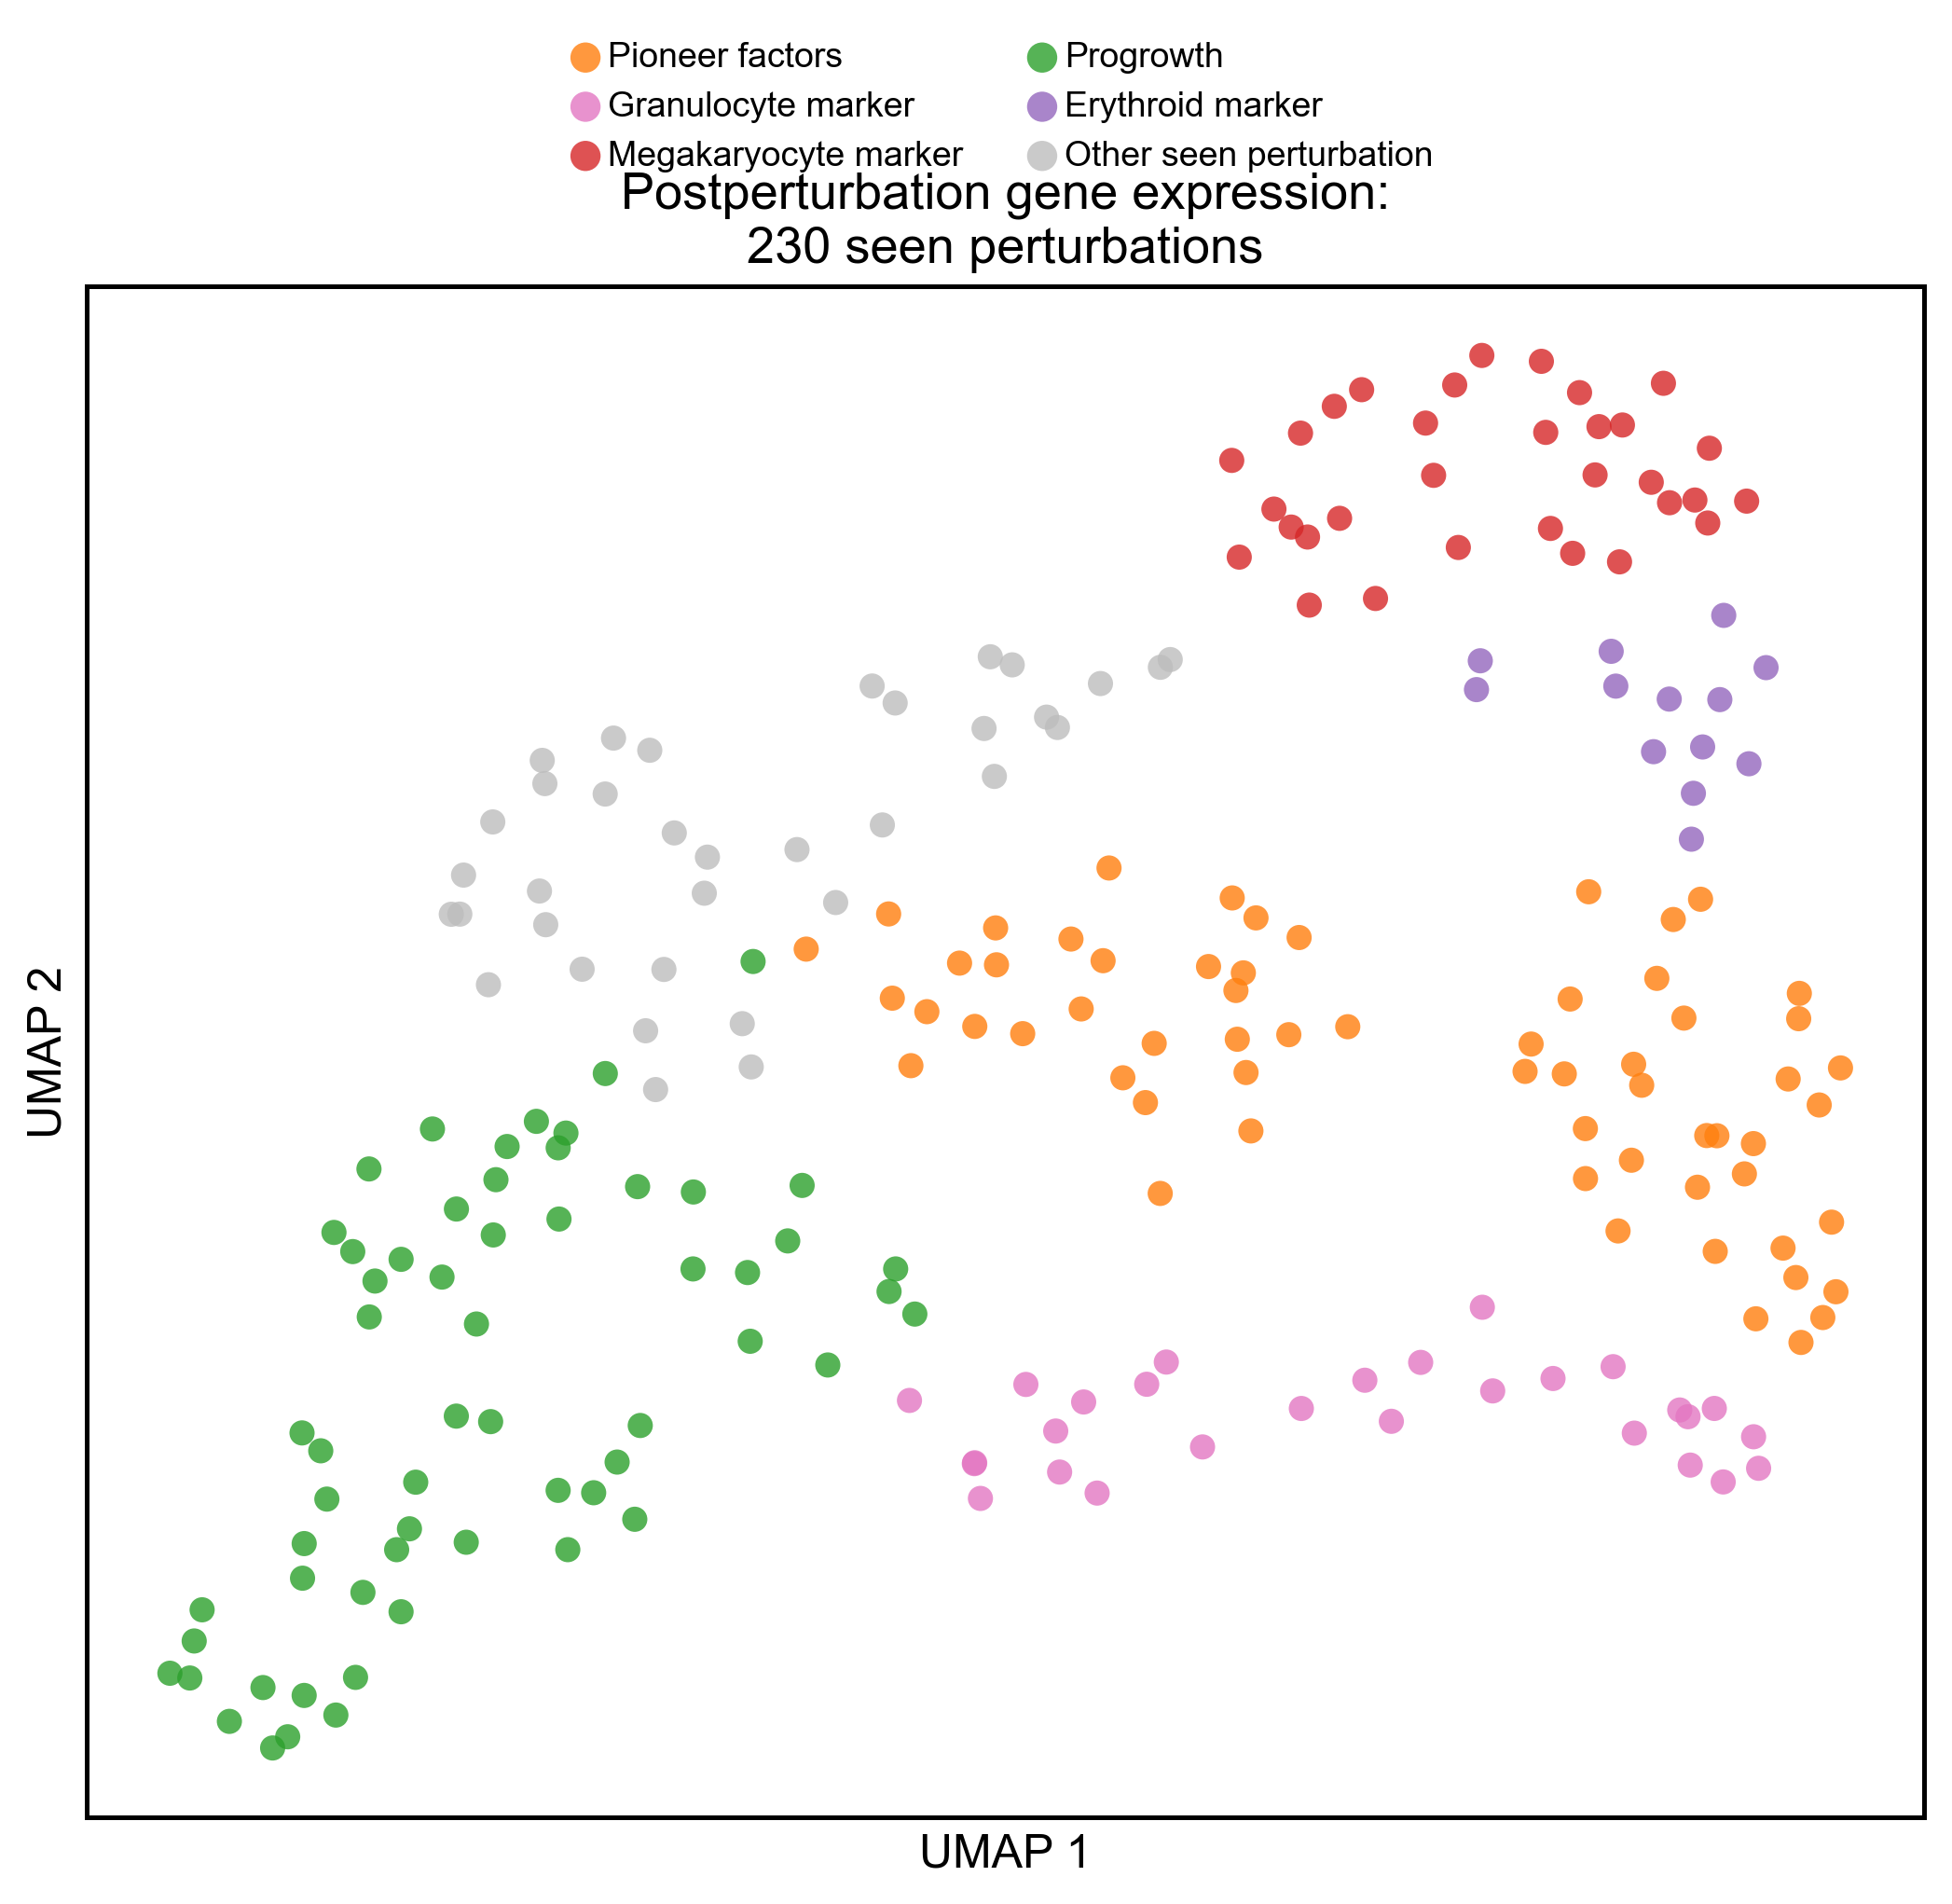

In [49]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

figure4b_order = [
    "Pioneer factors",
    "Granulocyte marker",
    "Megakaryocyte marker",
    "Progrowth",
    "Erythroid marker",
    "Other seen perturbation"
]

fig, ax = plt.subplots(
    figsize=(7.2, 7.0),
    dpi=150
)

for phenotype in figure4b_order:
    mask = (
        seen_adata.obs["phenotype_4b"]
        == phenotype
    )

    coordinates = seen_adata.obsm["X_umap"][mask]

    if len(coordinates) == 0:
        continue

    ax.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        s=42,
        c=paper_colors[phenotype],
        alpha=0.80,
        edgecolors="none",
        label=phenotype
    )

ax.set_xlabel("UMAP 1", fontsize=12)
ax.set_ylabel("UMAP 2", fontsize=12)

ax.set_title(
    "Postperturbation gene expression:\n"
    f"{seen_adata.n_obs} seen perturbations",
    fontsize=13
)

ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

ax.legend(
    frameon=False,
    fontsize=9,
    markerscale=1.2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=2
)

fig.tight_layout()

FIG4B_PNG = OUTPUT_DIR / "Figure4b_reproduced.png"
FIG4B_SVG = OUTPUT_DIR / "Figure4b_reproduced.svg"
FIG4B_PDF = OUTPUT_DIR / "Figure4b_reproduced.pdf"

fig.savefig(
    FIG4B_PNG,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIG4B_SVG,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIG4B_PDF,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

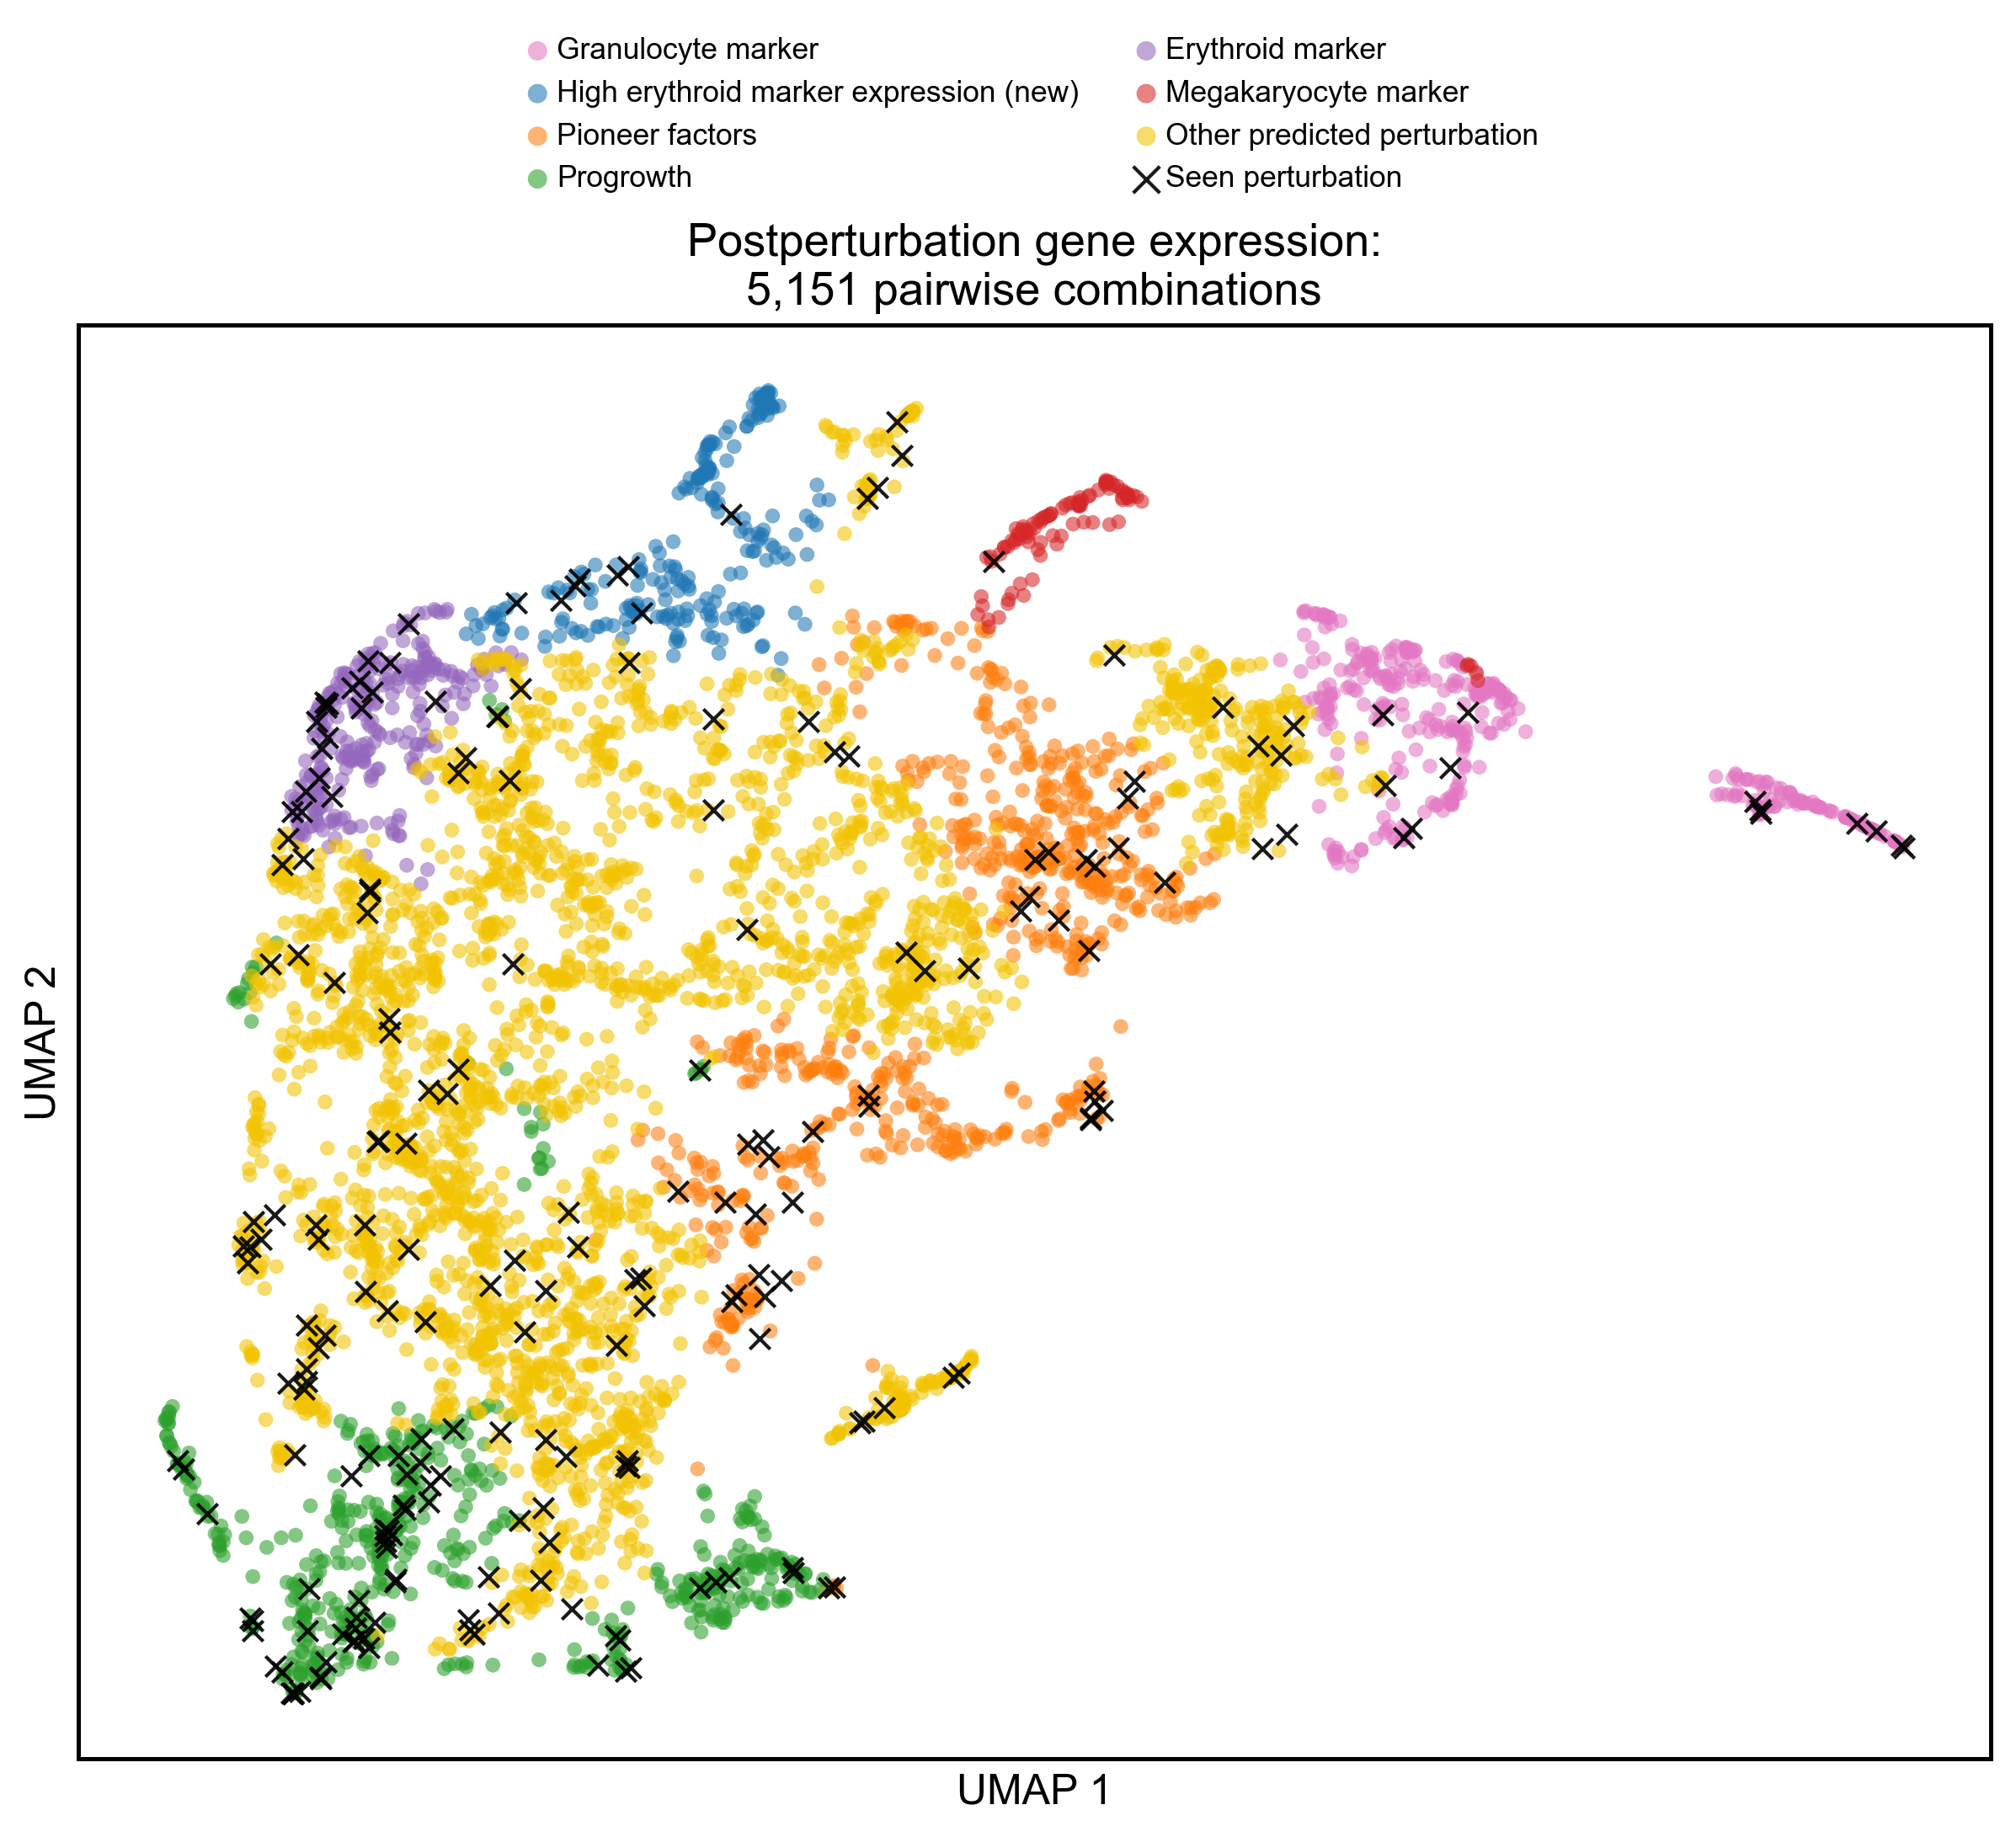

In [50]:
figure4c_order = [
    "Granulocyte marker",
    "High erythroid marker expression (new)",
    "Pioneer factors",
    "Progrowth",
    "Erythroid marker",
    "Megakaryocyte marker",
    "Other predicted perturbation"
]

fig, ax = plt.subplots(
    figsize=(8.2, 7.5),
    dpi=150
)

# 先画5023个未观察组合
unseen_mask = ~pred_adata.obs["seen"]

for phenotype in figure4c_order:
    mask = (
        unseen_mask
        & (
            pred_adata.obs["phenotype_4c"]
            == phenotype
        )
    )

    coordinates = pred_adata.obsm["X_umap"][mask]

    if len(coordinates) == 0:
        continue

    ax.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        s=18,
        c=paper_colors[phenotype],
        alpha=0.58,
        edgecolors="none",
        marker="o",
        label=phenotype
    )

# 最后画230个已观察扰动，使黑色叉号位于上层
seen_mask = pred_adata.obs["seen"]
seen_coordinates = pred_adata.obsm["X_umap"][seen_mask]

ax.scatter(
    seen_coordinates[:, 0],
    seen_coordinates[:, 1],
    s=34,
    c=paper_colors["Seen perturbation"],
    alpha=0.90,
    marker="x",
    linewidths=1.0,
    label="Seen perturbation",
    zorder=10
)

ax.set_xlabel("UMAP 1", fontsize=12)
ax.set_ylabel("UMAP 2", fontsize=12)

ax.set_title(
    "Postperturbation gene expression:\n"
    "5,151 pairwise combinations",
    fontsize=13
)

ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

ax.legend(
    frameon=False,
    fontsize=8.5,
    markerscale=1.3,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.22),
    ncol=2
)

fig.tight_layout()

FIG4C_PNG = OUTPUT_DIR / "Figure4c_reproduced.png"
FIG4C_SVG = OUTPUT_DIR / "Figure4c_reproduced.svg"
FIG4C_PDF = OUTPUT_DIR / "Figure4c_reproduced.pdf"

fig.savefig(
    FIG4C_PNG,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIG4C_SVG,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIG4C_PDF,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [51]:
FINAL_FULL_PATH = (
    OUTPUT_DIR
    / "figure4c_final_annotated.h5ad"
)

FINAL_SEEN_PATH = (
    OUTPUT_DIR
    / "figure4b_final_annotated.h5ad"
)

pred_adata.write_h5ad(
    FINAL_FULL_PATH,
    compression="gzip"
)

seen_adata.write_h5ad(
    FINAL_SEEN_PATH,
    compression="gzip"
)

print("Figure 4b：")
print(FIG4B_PNG)
print(FIG4B_SVG)
print(FIG4B_PDF)

print("\nFigure 4c：")
print(FIG4C_PNG)
print(FIG4C_SVG)
print(FIG4C_PDF)

print("\n带注释的数据：")
print(FINAL_SEEN_PATH)
print(FINAL_FULL_PATH)

Figure 4b：
F:\paper_reproduction\outputs\figure4\Figure4b_reproduced.png
F:\paper_reproduction\outputs\figure4\Figure4b_reproduced.svg
F:\paper_reproduction\outputs\figure4\Figure4b_reproduced.pdf

Figure 4c：
F:\paper_reproduction\outputs\figure4\Figure4c_reproduced.png
F:\paper_reproduction\outputs\figure4\Figure4c_reproduced.svg
F:\paper_reproduction\outputs\figure4\Figure4c_reproduced.pdf

带注释的数据：
F:\paper_reproduction\outputs\figure4\figure4b_final_annotated.h5ad
F:\paper_reproduction\outputs\figure4\figure4c_final_annotated.h5ad
